# Explorative Datenanalyse mit dem Iris-Datensatz

Ziel dieses Notebooks ist die Wiederholung zentraler Schritte der explorativen Datenanalyse **Exploratory Data Analysis (EDA)**. Verwendet wird der Iris-Datensatz aus `scikit-learn`. Er enthält vier metrische Merkmale von Iris-Blüten und deren Zugehörigkeit zu drei Arten.

## Lernziele

Nach der Bearbeitung können Sie:

- einen Datensatz laden und in einen `DataFrame` überführen,
- die Struktur, Datentypen und fehlende Werte prüfen,
- deskriptive Kennzahlen interpretieren,
- Verteilungen und Zusammenhänge visualisieren,
- potenzielle Features/Variablen für nachfolgende Modelle identifizieren.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pandas.plotting import scatter_matrix
from sklearn.datasets import load_iris

plt.rcParams['figure.figsize'] = (8, 5)

## 1. Daten laden

In [3]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 2. Struktur und Datenqualität

In [4]:
print('Form:', df.shape)
print('\nDatentypen:')
print(df.dtypes)
print('\nFehlende Werte:')
print(df.isna().sum())

Form: (150, 6)

Datentypen:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species               object
dtype: object

Fehlende Werte:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64


In [5]:
for i in df.columns:
    print(i)

sepal length (cm)
sepal width (cm)
petal length (cm)
petal width (cm)
target
species


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5
target,150.0,1.000000,0.819232,0.0,0.0,1.00,2.0,2.0


In [7]:
df.dtypes

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species               object
dtype: object

### Aufgabe 1

1. Welche Variablen besitzen die größte Streuung?
2. Gibt es Hinweise auf fehlende Werte (Missing Values)?
3. Welche Variable wäre als Zielvariable für eine **Klassifikationsaufgabe** mit dem vorhandenen Datensatz geeignet?

## 3. Klassenverteilung

In [8]:
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

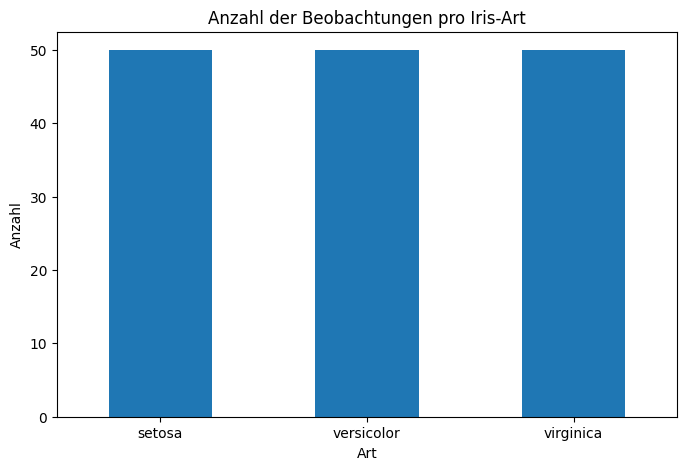

In [9]:
ax = df['species'].value_counts().plot(kind='bar')
ax.set_title('Anzahl der Beobachtungen pro Iris-Art')
ax.set_xlabel('Art')
ax.set_ylabel('Anzahl')
plt.xticks(rotation=0)
plt.show()

## 4. Univariate Verteilungen

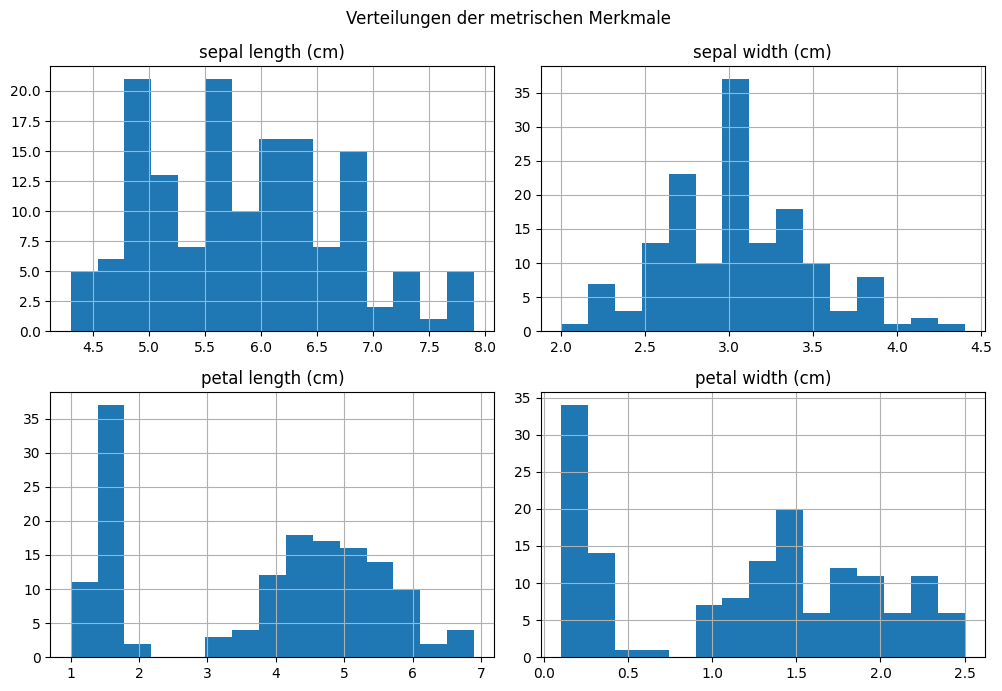

In [10]:
feature_cols = iris.feature_names
df[feature_cols].hist(bins=15, figsize=(10, 7))
plt.suptitle('Verteilungen der metrischen Merkmale')
plt.tight_layout()
plt.show()

### Aufgabe 2

Was fällt Ihnen an den Daten auf? Welche Unregelmäßigkeiten erkennen Sie und wie können Sie diese erklären?

## 5. Zusammenhänge zwischen Variablen

### Aufgabe 3

Wir wollen Korrelationen zwischen Variablen bestimmen. Welches Korrelationsmaß würden Sie heranziehen? Interpretieren Sie die Ergebnisse?

In [11]:
corr = df[feature_cols].corr()
corr.round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.00,-0.12,0.87,0.82
sepal width (cm),-0.12,1.00,-0.43,-0.37
petal length (cm),0.87,-0.43,1.00,0.96
petal width (cm),0.82,-0.37,0.96,1.00


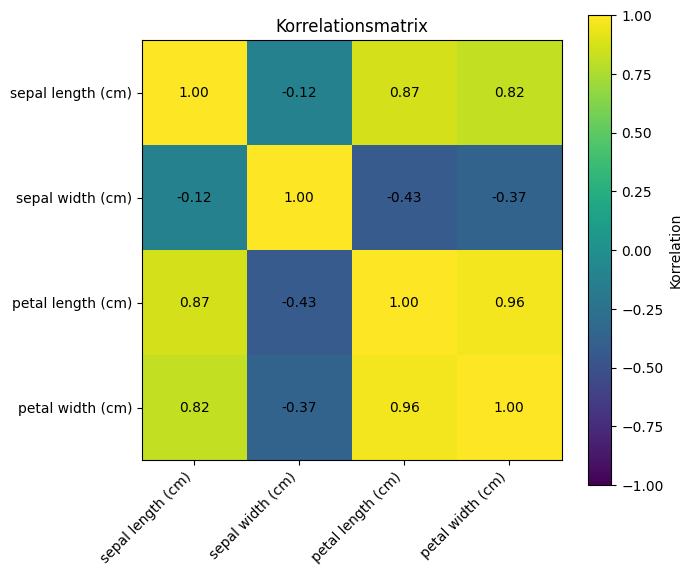

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_cols)), feature_cols, rotation=45, ha='right')
ax.set_yticks(range(len(feature_cols)), feature_cols)
for i in range(len(feature_cols)):
    for j in range(len(feature_cols)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')
ax.set_title('Korrelationsmatrix')
fig.colorbar(im, ax=ax, label='Korrelation')
plt.tight_layout()
plt.show()

## 6. Scatter-Matrix

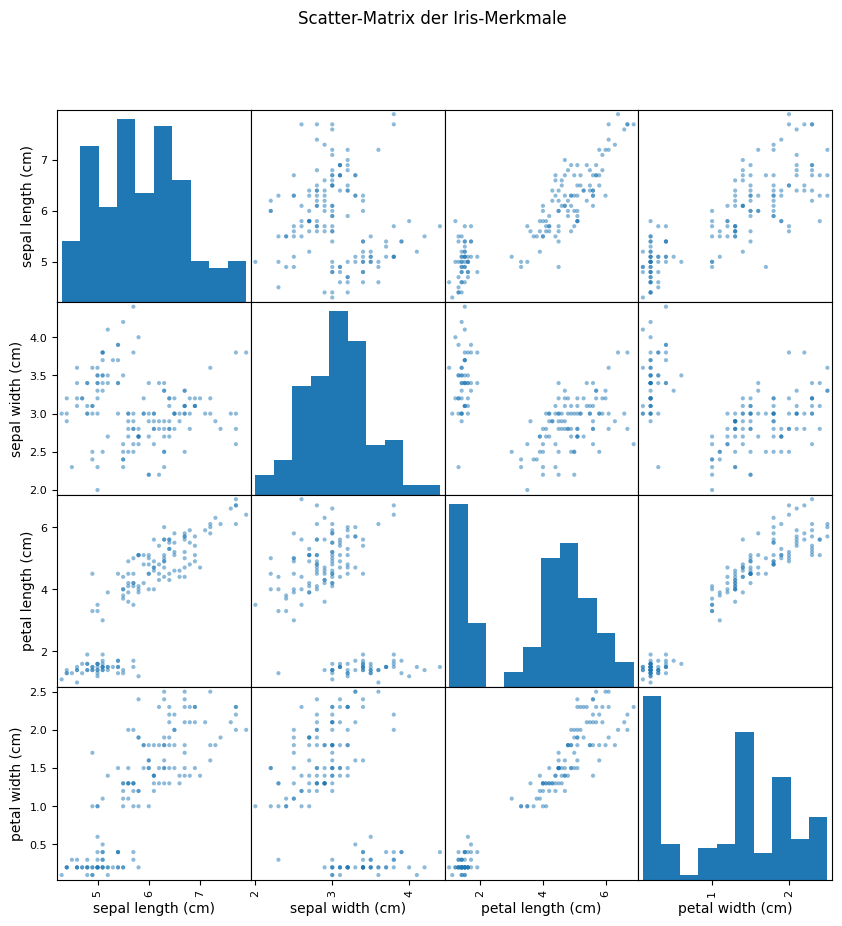

In [13]:
scatter_matrix(df[feature_cols], figsize=(10, 10), diagonal='hist')
plt.suptitle('Scatter-Matrix der Iris-Merkmale')
plt.show()

## 7. Ein Zusammenhang im Detail

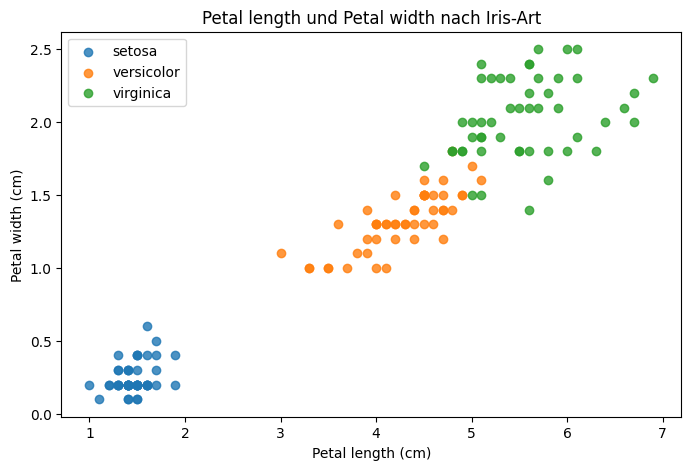

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
for species in iris.target_names:
    subset = df[df['species'] == species]
    ax.scatter(subset['petal length (cm)'], subset['petal width (cm)'], label=species, alpha=0.8)
ax.set_xlabel('Petal length (cm)')
ax.set_ylabel('Petal width (cm)')
ax.set_title('Petal length und Petal width nach Iris-Art')
ax.legend()
plt.show()

### Aufgabe 3

1. Welche Merkmale zeigen einen besonders starken linearen Zusammenhang?
2. Welche Arten lassen sich anhand der dargestellten Merkmale visuell gut trennen?
3. Weshalb ist der Iris-Datensatz trotz linearer Zusammenhänge primär ein **Klassifikationsdatensatz**?

## 8. Gruppierte deskriptive Statistik

In [15]:
df.groupby('species')[feature_cols].mean().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


## 9. Zusammenfassung

Die EDA zeigt, dass insbesondere Länge und Breite der Blütenblätter stark zusammenhängen und sich die drei Arten in mehreren Merkmalen unterscheiden. Für die spätere Einführung der linearen Regression verwenden wir dennoch einen Datensatz mit **metrischer Zielvariable**, weil die Iris-Zielvariable eine Kategorie darstellt. Für die Klassifikation wird Iris später wieder aufgegriffen.